# Assignment 3: Data preprocessing of historical tropical cyclone records

In this assignment you will explore and preprocess a global collection of tropical cyclone
records, the International Best Track Archive for Climate Stewardship
[(IBTrACS)](https://www.ncei.noaa.gov/products/international-best-track-archive). The column
descriptions are given
[here](https://www.ncei.noaa.gov/sites/default/files/2025-09/IBTrACS_v04r01_column_documentation.pdf).
IBTrACS is the World Meteorological Organization's official archive of global tropical cyclone
tracks, assembled from every regional forecast centre. It is real operational data, which means it
is messy: reporting practices differ by basin and have changed over time.

The five parts follow the Weeks 2 and 3 material: look at the data, handle missing values, scale,
encode, and split. Assignment 4 models the same records once they are clean.

Answer each numbered question in the empty cell below it.


In [2]:
from math import isnan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing

## Load and aggregate the data set
Using the following code, load in the data set (this takes a few seconds to run: the full archive is a large file):


In [3]:
url = 'https://www.ncei.noaa.gov/data/international-best-track-archive-for-climate-stewardship-ibtracs/v04r01/access/csv/ibtracs.ALL.list.v04r01.csv'
df = pd.read_csv(url, parse_dates=['ISO_TIME'], usecols=range(12),
                 skiprows=[1], na_values=[' ', 'NOT_NAMED'],
                 keep_default_na=False, dtype={'NAME': str})

This data set includes cyclone tracks (so it has multiple entries per named cyclone). We'll use the code below to create an aggregated data set for only the named cyclones, which has one entry per cyclone. You will use the data set `dfnamed` for the rest of the assignment.

In [4]:
dfnamed = df.groupby("NAME").agg(MAX_WIND=('WMO_WIND','max'),
                               MIN_PRES=('WMO_PRES','min'),
                               MEAN_LAT=('LAT','mean'),
                               MEAN_LON=('LON','mean'),
                               BASIN=('BASIN','first'),
                               SUBBASIN=('SUBBASIN','first'),
                               NATURE=('NATURE','first'),
                               SEASON=('SEASON','first')).reset_index()
print(dfnamed.head())

# these lines of code remove the initial dataframe (we won't need it anymore)
import gc
del df
gc.collect()

        NAME  MAX_WIND  MIN_PRES   MEAN_LAT    MEAN_LON BASIN SUBBASIN NATURE  \
0    ABAIMBA      43.0     995.0  -4.637234   63.031915    SI       MM     TS   
1       ABBY     120.0     895.0  20.905938   74.640937    NA       NA     TS   
2        ABE      85.0     945.0  22.272561  128.743293    WP       MM     NR   
3  ABEL:BETH      60.0     975.0  15.482927  131.466667    WP       MM     NR   
4      ABELA      50.0     987.0 -10.850769   65.370769    SI       MM     DS   

   SEASON  
0    2003  
1    1960  
2    1990  
3    1996  
4    2017  


194

## Part 1: Data Exploration

How many named cyclones are there?

In [5]:
len(dfnamed)

1909

1) Use the `pandas` `hist` method to plot the marginal distributions of the variables in the dataframe `dfnamed`

array([[<Axes: title={'center': 'MAX_WIND'}>,
        <Axes: title={'center': 'MIN_PRES'}>],
       [<Axes: title={'center': 'MEAN_LAT'}>,
        <Axes: title={'center': 'MEAN_LON'}>],
       [<Axes: title={'center': 'SEASON'}>, <Axes: >]], dtype=object)

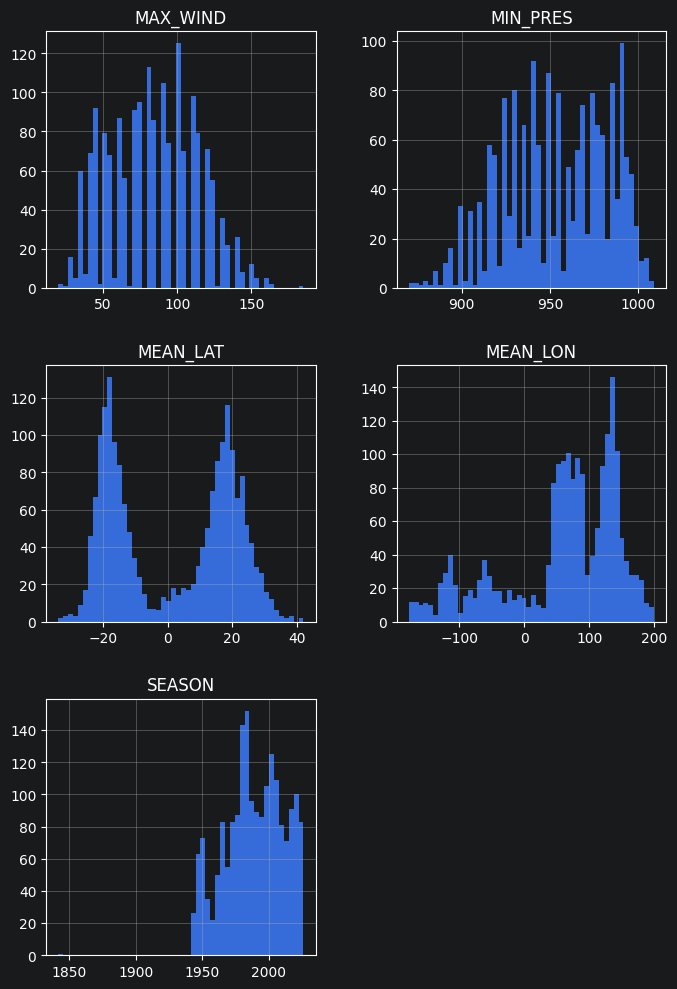

In [6]:
dfnamed.hist(bins=50, figsize=(8,12))

2) Use the `seaborn` Pairgrid function to create a scatterplot of all of the variables

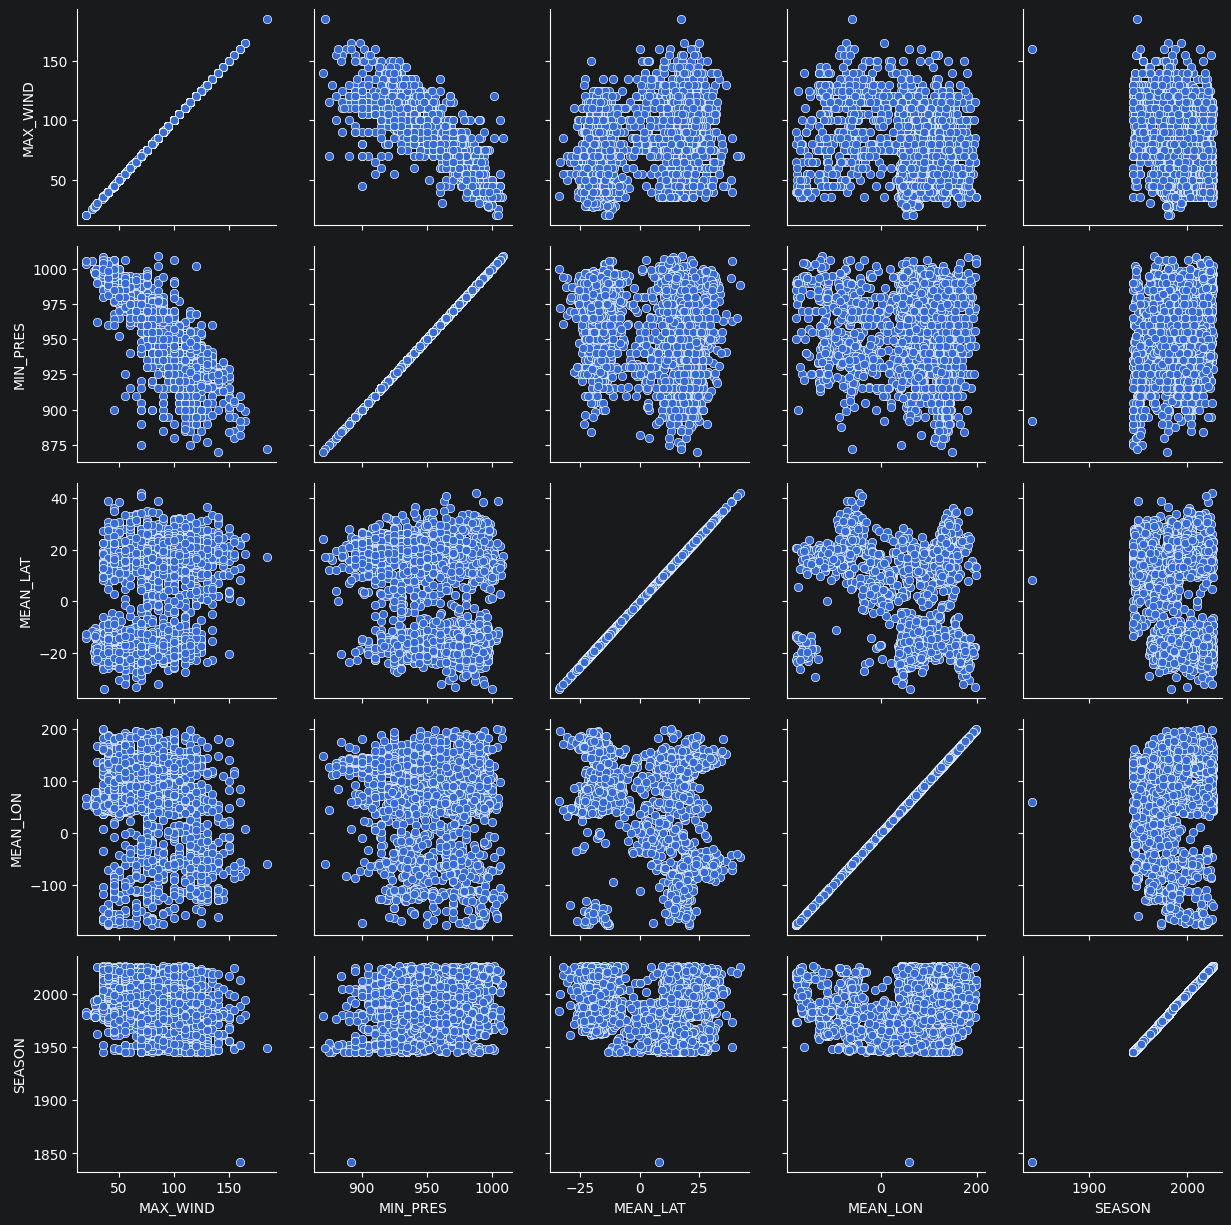

In [7]:
g = sns.PairGrid(dfnamed)
g.map(sns.scatterplot)

3) Using `matplotlib`, create a scatter plot of the minimum pressure vs. the maximum wind speed and color by the year the cyclone took place.

<Axes: xlabel='MIN_PRES', ylabel='MAX_WIND'>

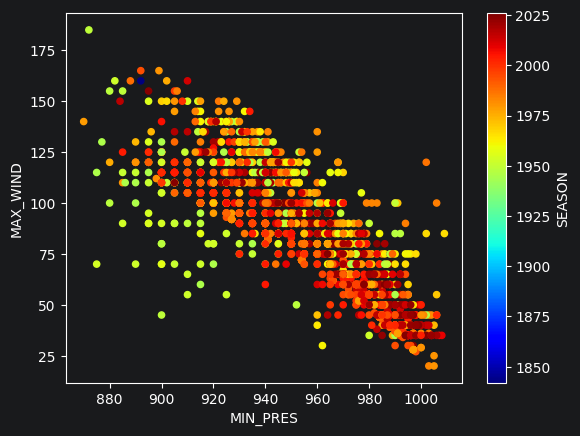

In [8]:
dfnamed.plot(kind='scatter', x='MIN_PRES', y='MAX_WIND', c='SEASON', cmap='jet')

## Part 2: Handle missing data
4) How many non-null values does each variable have?

In [9]:
dfnamed.count()

NAME        1909
MAX_WIND    1730
MIN_PRES    1741
MEAN_LAT    1909
MEAN_LON    1909
BASIN       1909
SUBBASIN    1909
NATURE      1909
SEASON      1909
dtype: int64

5) Create a new dataframe called `dfdrop` where you have discarded the rows with NaN values in `dfnamed`

In [10]:
dfdrop = dfnamed.dropna().copy()

6) Create a new dataframe called `dfimputed` where you have imputed the missing values in `dfnamed` with 0.0.

In [11]:
dfimputed = dfnamed.fillna(0.0).copy()

## Part 3: Feature scaling

7) Scale the `MAX_WIND` column of your `dfdrop` dataframe using the StandardScaler and put it into an array called `y`, since it's the target we want to predict 

*Hint*: the `StandardScaler` expects a 2-D input, so reshape your column with `.values.reshape(-1, 1)` before scaling.

In [24]:
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

standard_scaler = StandardScaler()
y = standard_scaler.fit_transform(dfdrop['MAX_WIND'].values.reshape(-1,1))
y

array([[-1.39083936],
       [ 1.20069059],
       [ 0.02272243],
       ...,
       [ 1.53725292],
       [-0.3138399 ],
       [-0.14555874]])

8) Create a copy of your `dfdrop` dataframe called `dffeatures`, and drop the `NAME` and `MAX_WIND` columns from your `dffeatures` dataframe, since the `MAX_WIND` variable is going to be your target variable and we won't need the cyclone names any longer

In [13]:
dffeatures = dfdrop.drop(columns=['NAME', 'MAX_WIND']).copy()
dffeatures

,MIN_PRES,MEAN_LAT,MEAN_LON,BASIN,SUBBASIN,NATURE,SEASON
0,995.0,-4.637234,63.031915,SI,MM,TS,2003
1,895.0,20.905938,74.640937,NA,NA,TS,1960
2,945.0,22.272561,128.743293,WP,MM,NR,1990
3,975.0,15.482927,131.466667,WP,MM,NR,1996
4,987.0,-10.850769,65.370769,SI,MM,DS,2017
...,...,...,...,...,...,...,...
1904,985.0,30.488889,139.937037,WP,MM,TS,1999
1905,975.0,-2.877381,-37.791667,WP,MM,NR,1997
1906,890.0,-23.491903,165.836437,SP,EA,TS,1974
1907,960.0,29.576316,143.153289,WP,MM,NR,1990


## Part 4: Encode Categorical Variables
9) Check which unique categories each of the variables `BASIN`, `SUBBASIN`, and `NATURE` take, using the `dffeatures` dataframe.

In [14]:
dffeatures['BASIN'].unique()

array(['SI', 'NA', 'WP', 'SP', 'EP', 'NI'], dtype=object)

In [15]:
dffeatures['SUBBASIN'].unique()

array(['MM', 'NA', 'EA', 'WA', 'BB', 'CP', 'GM', 'AS', 'CS'], dtype=object)

In [16]:
dffeatures['NATURE'].unique()

array(['TS', 'NR', 'DS', 'MX', 'SS', 'ET'], dtype=object)

10) Print out the number of cyclones in each basin and subbasin. Also print out how many of each storm type there is.

In [17]:
dffeatures.groupby(['BASIN', 'SUBBASIN']).size()

BASIN  SUBBASIN
EP     CP           33
       MM          142
NA     CS           36
       GM           25
       NA          113
NI     AS           26
       BB           52
SI     MM          351
       WA          202
SP     EA           89
       MM          160
WP     MM          464
dtype: int64

In [18]:
dffeatures.groupby(['BASIN', 'SUBBASIN', 'NATURE']).size()
dffeatures

,MIN_PRES,MEAN_LAT,MEAN_LON,BASIN,SUBBASIN,NATURE,SEASON
0,995.0,-4.637234,63.031915,SI,MM,TS,2003
1,895.0,20.905938,74.640937,NA,NA,TS,1960
2,945.0,22.272561,128.743293,WP,MM,NR,1990
3,975.0,15.482927,131.466667,WP,MM,NR,1996
4,987.0,-10.850769,65.370769,SI,MM,DS,2017
...,...,...,...,...,...,...,...
1904,985.0,30.488889,139.937037,WP,MM,TS,1999
1905,975.0,-2.877381,-37.791667,WP,MM,NR,1997
1906,890.0,-23.491903,165.836437,SP,EA,TS,1974
1907,960.0,29.576316,143.153289,WP,MM,NR,1990


11) Encode the `BASIN`, `SUBBASIN`, and `NATURE` variables in `dffeatures` using One Hot Encoding, and standardize `MIN_PRES`, `MEAN_LAT`, and `MEAN_LON`, and `SEASON` using the `StandardScaler`.

*Hint*: you can do this in one step using the `sci-kit learn` `ColumnTransformer`. Create an array called `X` that contains the encoded categorical variables and the scaled numerical variables.

In [19]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer

categorical_columns = ['BASIN', 'SUBBASIN', 'NATURE']
numerical_columns = ['MIN_PRES', 'MEAN_LAT', 'MEAN_LON', 'SEASON']
categorical_pipeline = make_pipeline(OneHotEncoder())
numerical_pipeline = make_pipeline(StandardScaler())

preprocessor = ColumnTransformer([('num', numerical_pipeline, numerical_columns),
                                  ('cat', categorical_pipeline, categorical_columns)])


In [20]:
X = preprocessor.fit_transform(dffeatures)

12) Print out the feature names associated with the columns in your `X` array.

In [21]:
preprocessor.get_feature_names_out()

array(['num__MIN_PRES', 'num__MEAN_LAT', 'num__MEAN_LON', 'num__SEASON',
       'cat__BASIN_EP', 'cat__BASIN_NA', 'cat__BASIN_NI', 'cat__BASIN_SI',
       'cat__BASIN_SP', 'cat__BASIN_WP', 'cat__SUBBASIN_AS',
       'cat__SUBBASIN_BB', 'cat__SUBBASIN_CP', 'cat__SUBBASIN_CS',
       'cat__SUBBASIN_EA', 'cat__SUBBASIN_GM', 'cat__SUBBASIN_MM',
       'cat__SUBBASIN_NA', 'cat__SUBBASIN_WA', 'cat__NATURE_DS',
       'cat__NATURE_ET', 'cat__NATURE_MX', 'cat__NATURE_NR',
       'cat__NATURE_SS', 'cat__NATURE_TS'], dtype=object)

## Part 5: Train, Validation, & Test Split

13) Split your data set into a training and test/validation data set using the `train_test_split` function with 80% of your original data for training and 20% for the testing and validation data sets.

In [25]:
from sklearn.model_selection import train_test_split
X_train, X_test_val, y_train, y_test_val = train_test_split(X, y, test_size=0.2, random_state=27)


14) Split your `X_test_val` and `y_test_val` again into separate validation and test data sets, that are 10% each of the original data set. Double check that the size of your final training, validation, and test data sets are correct by printing out the shape of each array.

In [26]:
X_val, X_test, y_val, y_test = train_test_split(X_test_val, y_test_val, test_size = 0.5, random_state=42)

In [27]:
print(X_train.shape, X_val.shape, X_test.shape)

(1354, 25) (169, 25) (170, 25)


15) Save the Training, validation, and test data sets and labels as numpy arrays using np.save()

In [28]:
np.save('X_train.npy', X_train)
np.save('X_val.npy',   X_val)
np.save('X_test.npy',  X_test)
np.save('y_train.npy', y_train)
np.save('y_val.npy',   y_val)
np.save('y_test.npy',  y_test)